Вариант 8.

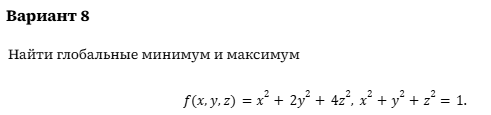

In [4]:
import sympy as sp
EPS = 1e-8  # Критерий точности невязки

x, y, z = sp.symbols("x y z", real=True)
lam = sp.symbols("lambda", real=True)

f = x**2 + 2*y**2 + 4*z**2
constraints = [x**2 + y**2 + z**2 - 1]  #ограничения
variables = [x, y, z]  #переменные
multipliers = [lam] #лямбды
#функция Лагранжа в общем случае(для нескольких ограничений)
L = f + sum(a * h for a, h in zip(multipliers, constraints))
#система неравенств
equations = [sp.diff(L, v) for v in variables] + constraints
#неизвестные переменные и множители Лагранжа
unknowns = variables + multipliers

print(f"Целевая функция: {f}")
print(f"Ограничения: {constraints[0]} = 0")
print(f"Функция Лагранжа: {L}")
print("Уравнения стационарности:")
for eq in equations:
    print(f"  {eq} = 0")

# поиск решений
solutions = sp.solve(equations, unknowns, dict=True)

valid_candidates = []

print("\nПроверка кандидатов")
# цикл перебора решений с использованием point_subs и residuals
for number, solution in enumerate(solutions, start=1):
    point_subs = {v: solution[v] for v in variables}
    # подстановка и упрощение невязок по методичке
    residuals = [sp.simplify(h.subs(point_subs)) for h in constraints]
    value = sp.simplify(f.subs(point_subs))

    # извлечение значения лямбды для вывода
    lam_val = solution[lam]

    # определение допустимости по константе EPS
    is_feasible = all(abs(float(res)) <= EPS for res in residuals)

    if is_feasible:
        # переводим координаты в удобный кортеж
        pt = tuple(solution[v] for v in variables)
        valid_candidates.append({"point": pt, "value": value})

    print(f"Кандидат {number}:")
    print(f" точка: {tuple(solution[v] for v in variables)}")
    print(f" множители: {lam_val}")
    print(f" значение функции: {value}")
    print(f" невязки ограничений: {residuals[0]}")
    print(f" допустимость: {'да' if is_feasible else 'нет'}")

#Выбор глобального минимума и максимума на основе валидных точек
f_min = min(c["value"] for c in valid_candidates)
f_max = max(c["value"] for c in valid_candidates)

min_points = [c["point"] for c in valid_candidates if c["value"] == f_min]
max_points = [c["point"] for c in valid_candidates if c["value"] == f_max]

print("\nИтог:")
print(f" глобальный минимум: {f_min} в точках {min_points}")
print(f" глобальный максимум: {f_max} в точках {max_points}")
print(" основание классификации: допустимое множество (сфера) является компактом, "
      "целевая функция непрерывна. По теореме Вейерштрасса глобальные экстремумы существуют "
      "и находятся среди стационарных точек путем прямого сравнения их значений.")


Целевая функция: x**2 + 2*y**2 + 4*z**2
Ограничения: x**2 + y**2 + z**2 - 1 = 0
Функция Лагранжа: lambda*(x**2 + y**2 + z**2 - 1) + x**2 + 2*y**2 + 4*z**2
Уравнения стационарности:
  2*lambda*x + 2*x = 0
  2*lambda*y + 4*y = 0
  2*lambda*z + 8*z = 0
  x**2 + y**2 + z**2 - 1 = 0

Проверка кандидатов
Кандидат 1:
 точка: (0, 0, -1)
 множители: -4
 значение функции: 4
 невязки ограничений: 0
 допустимость: да
Кандидат 2:
 точка: (0, 0, 1)
 множители: -4
 значение функции: 4
 невязки ограничений: 0
 допустимость: да
Кандидат 3:
 точка: (0, -1, 0)
 множители: -2
 значение функции: 2
 невязки ограничений: 0
 допустимость: да
Кандидат 4:
 точка: (0, 1, 0)
 множители: -2
 значение функции: 2
 невязки ограничений: 0
 допустимость: да
Кандидат 5:
 точка: (-1, 0, 0)
 множители: -1
 значение функции: 1
 невязки ограничений: 0
 допустимость: да
Кандидат 6:
 точка: (1, 0, 0)
 множители: -1
 значение функции: 1
 невязки ограничений: 0
 допустимость: да

Итог:
 глобальный минимум: 1 в точках [(-1, 0, 0